In [26]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score,r2_score

In [27]:
df=pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\Wisconsin\BreastCancer.csv",index_col=0)
X,y=df.drop('Class',axis=1),df['Class']
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=26,test_size=.3,stratify=y)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [28]:
rf=RandomForestClassifier(n_estimators=50,random_state=26)
rf.fit(X_train,y_train)
pred=rf.predict(X_test)
accuracy_score(y_test,pred)


0.9666666666666667

In [29]:
rf.feature_importances_

array([0.05352196, 0.28682289, 0.27440192, 0.03494217, 0.0909838 ,
       0.1288429 , 0.05543484, 0.0629868 , 0.01206271])

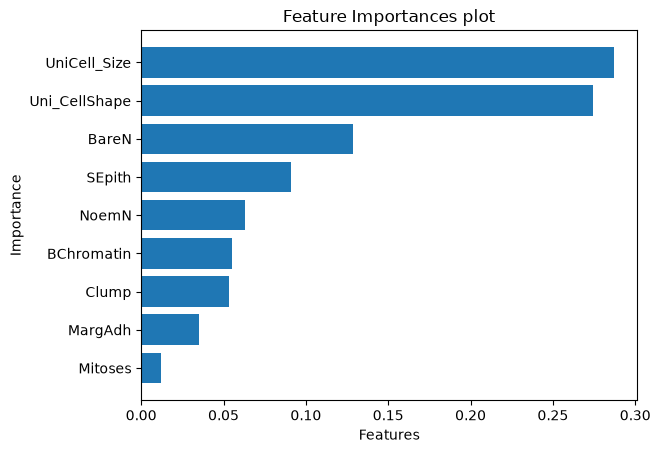

In [30]:
df_imp = pd.DataFrame({'features': list(X.columns),
                       'importance': rf.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()

In [31]:
df_imp

,features,importance
8,Mitoses,0.012063
3,MargAdh,0.034942
0,Clump,0.053522
6,BChromatin,0.055435
7,NoemN,0.062987
4,SEpith,0.090984
5,BareN,0.128843
2,Uni_CellShape,0.274402
1,UniCell_Size,0.286823


In [32]:
m_feat = [2,3,4,5]
n_samples = [10,25,50,100]
scores = []
for m in m_feat:
    for n in n_samples:
        bag = RandomForestClassifier(n_estimators = n,max_features=m, random_state=26)
        bag.fit(X_train, y_train)
        pred = bag.predict(X_test)
        scores.append([m,n, accuracy_score(y_test, pred)])
df_scores = pd.DataFrame(scores, columns=['Features','n_estimator','Score'])
df_scores.sort_values('Score', ascending = False, ignore_index = True)

,Features,n_estimator,Score
0,2,10,0.966667
1,2,25,0.966667
2,2,50,0.966667
3,2,100,0.966667
4,3,100,0.966667
5,3,50,0.966667
6,4,50,0.966667
7,4,100,0.966667
8,5,50,0.966667
9,5,100,0.966667


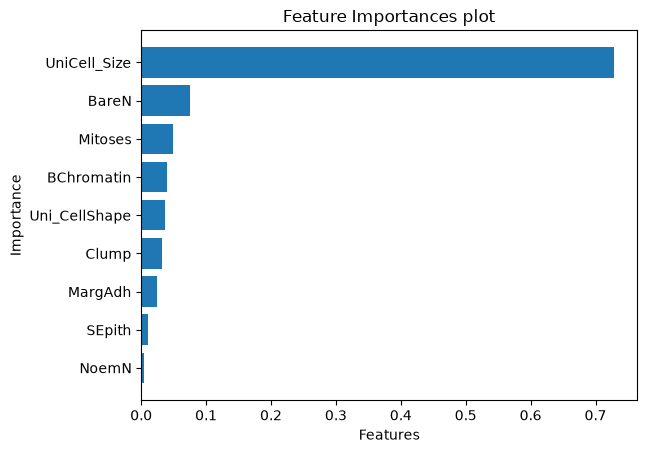

In [37]:
rf = RandomForestClassifier(n_estimators = 2, random_state=26)
rf.fit(X_train, y_train)

df_imp = pd.DataFrame({'features': list(X.columns),
                       'importance': rf.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()


In [38]:
rf.feature_importances_

array([0.03214348, 0.72777634, 0.03744201, 0.02392958, 0.01097001,
       0.07489564, 0.03976705, 0.00378901, 0.04928689])

In [ ]:
concrete = pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\Concrete_Strength\Concrete_Data.csv")
X,y=concrete.drop('Strength',axis=1),concrete.Strength
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=26)

In [ ]:
concrete.head()

In [ ]:
rf = RandomForestRegressor(n_estimators= 50, random_state = 26)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
r2_score(y_test, pred)

In [ ]:
df_imp = pd.DataFrame({'features': list(X.columns),
                       'importance': rf.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()